# Exploratory Data Analysis — PlantVillage

## Mục tiêu
Khảo sát bộ ảnh lá cây và nhãn được xác định từ tên thư mục lớp. Mỗi lớp biểu diễn một loại cây và tình trạng sức khỏe hoặc bệnh tương ứng.

## Định hướng
Đây là bài toán phân loại ảnh nhiều lớp. EDA tập trung vào số lượng ảnh mỗi lớp, định dạng và kích thước ảnh, ảnh lỗi hoặc trùng lặp, cùng các đặc điểm hình ảnh có thể ảnh hưởng đến mô hình.

## Lưu ý
Không nạp toàn bộ ảnh vào bộ nhớ cùng lúc. Các bước chia tập và đánh giá mô hình cần giữ nguyên nhãn lớp, tránh rò rỉ ảnh trùng giữa các tập.

Data Loading

Thư mục dữ liệu: C:\Users\TIEN DAT\OneDrive\Pictures\AI_Projects\04_PlantVillage\data\raw\content\PlantVillage_color
Số lớp: 38
Tổng số ảnh: 54,381
Các định dạng ảnh: ['.jpg']


,image_count
class_name,
Orange___Haunglongbing_(Citrus_greening),5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
Soybean___healthy,5090
Peach___Bacterial_spot,2297
Tomato___Bacterial_spot,2137
Tomato___Late_blight,1909
Squash___Powdery_mildew,1835
Tomato___Septoria_leaf_spot,1771
Tomato___Spider_mites Two-spotted_spider_mite,1676


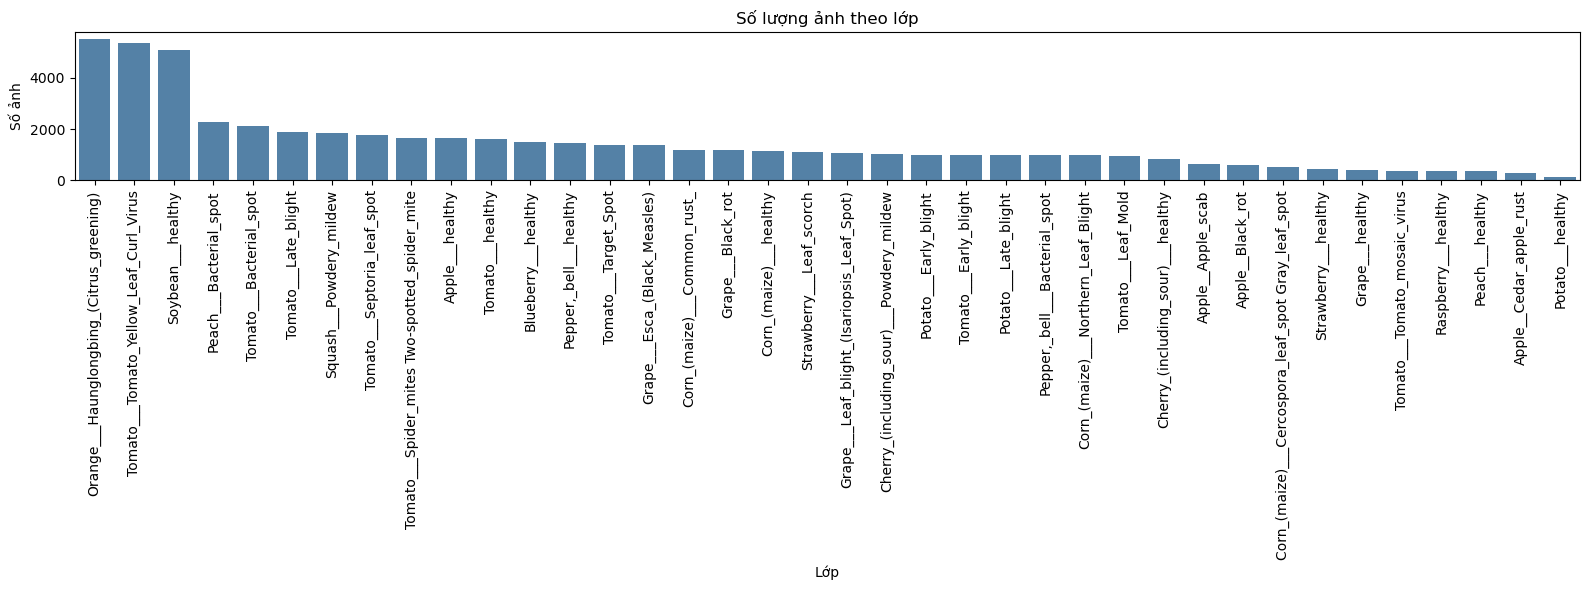

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Hỗ trợ cả trường hợp notebook chạy từ thư mục notebooks/ hoặc thư mục project
candidate_roots = [
    Path("../data/raw/content/PlantVillage_color"),
    Path("data/raw/content/PlantVillage_color"),
]

IMAGE_ROOT = next((path for path in candidate_roots if path.is_dir()), None)

if IMAGE_ROOT is None:
    checked_paths = "\n".join(str(path.resolve()) for path in candidate_roots)
    raise FileNotFoundError(
        "Không tìm thấy thư mục ảnh. Đã kiểm tra:\n" + checked_paths
    )

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_dirs = sorted(path for path in IMAGE_ROOT.iterdir() if path.is_dir())

if not class_dirs:
    raise ValueError(f"Không tìm thấy thư mục lớp trong: {IMAGE_ROOT.resolve()}")

records = []

for class_dir in class_dirs:
    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "path": str(image_path),
                "class_name": class_dir.name,
                "extension": image_path.suffix.lower(),
                "size_bytes": image_path.stat().st_size,
            })

images = pd.DataFrame(records)

if images.empty:
    raise ValueError(
        f"Không tìm thấy ảnh có đuôi {sorted(IMAGE_EXTENSIONS)} "
        f"trong {IMAGE_ROOT.resolve()}"
    )

# Tách tên cây và tình trạng nếu tên lớp có dạng crop___condition
class_parts = images["class_name"].str.split("___", n=1, expand=True)
images["crop"] = class_parts[0]
images["condition"] = (
    class_parts[1] if class_parts.shape[1] > 1 else pd.NA
)

class_counts = (
    images["class_name"]
    .value_counts()
    .reindex([path.name for path in class_dirs], fill_value=0)
    .rename_axis("class_name")
    .rename("image_count")
    .sort_values(ascending=False)
)

print(f"Thư mục dữ liệu: {IMAGE_ROOT.resolve()}")
print(f"Số lớp: {len(class_dirs)}")
print(f"Tổng số ảnh: {len(images):,}")
print(f"Các định dạng ảnh: {sorted(images['extension'].unique())}")
display(class_counts.to_frame())

plt.figure(figsize=(16, 6))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Số lượng ảnh theo lớp")
plt.xlabel("Lớp")
plt.ylabel("Số ảnh")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Dataset Overview

Lớp chưa tách được: []
Số loại cây: 14
Số nhãn tình trạng: 21

Số ảnh theo loại cây:


,image_count
crop,
Tomato,18204
Orange,5507
Soybean,5090
Grape,4062
Corn_(maize),3853
Apple,3202
Peach,2657
"Pepper,_bell",2475
Potato,2152



Số ảnh theo tình trạng:


,image_count
condition,
healthy,15138
Haunglongbing_(Citrus_greening),5507
Bacterial_spot,5431
Tomato_Yellow_Leaf_Curl_Virus,5357
Late_blight,2909
Powdery_mildew,2887
Early_blight,2000
Black_rot,1801
Septoria_leaf_spot,1771



Thống kê số ảnh trên mỗi lớp:
Số lớp: 38
Ít nhất: 152
Trung bình: 1,431.1
Nhiều nhất: 5,507
Tỷ lệ lớp nhiều nhất / ít nhất: 36.2 lần


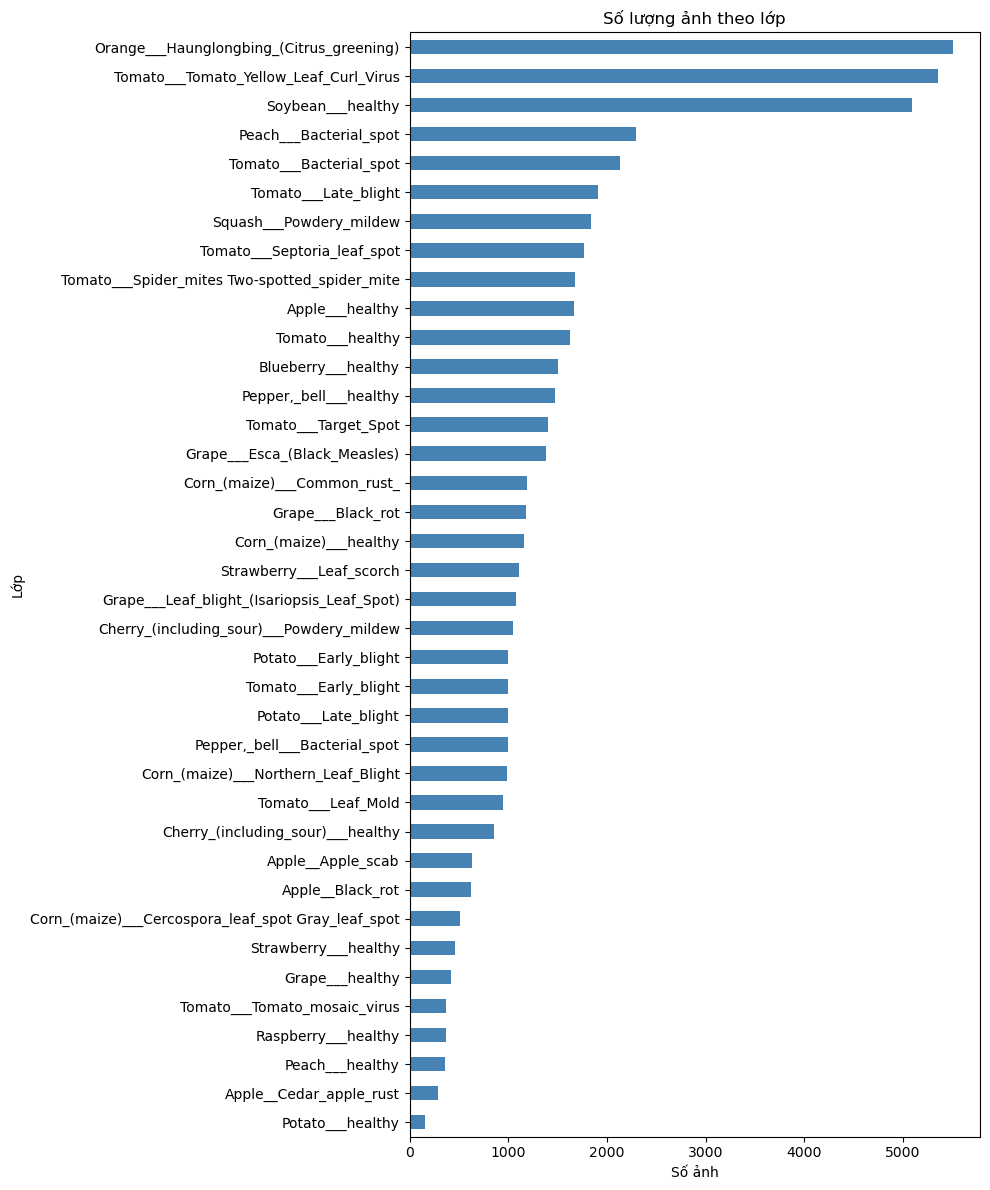

In [6]:
class_parts = images["class_name"].str.extract(
    r"^(?P<crop>.+?)_{2,}(?P<condition>.+)$"
)

images["crop"] = class_parts["crop"]
images["condition"] = class_parts["condition"]

print("Lớp chưa tách được:",
      images.loc[images["crop"].isna(), "class_name"].unique().tolist())

print("Số loại cây:", images["crop"].nunique())
print("Số nhãn tình trạng:", images["condition"].nunique())

print("\nSố ảnh theo loại cây:")
display(
    images.groupby("crop").size()
    .sort_values(ascending=False)
    .rename("image_count")
    .to_frame()
)

print("\nSố ảnh theo tình trạng:")
display(
    images.groupby("condition").size()
    .sort_values(ascending=False)
    .rename("image_count")
    .to_frame()
)

print("\nThống kê số ảnh trên mỗi lớp:")
print(f"Số lớp: {class_counts.size}")
print(f"Ít nhất: {class_counts.min():,}")
print(f"Trung bình: {class_counts.mean():,.1f}")
print(f"Nhiều nhất: {class_counts.max():,}")
print(f"Tỷ lệ lớp nhiều nhất / ít nhất: {class_counts.max() / class_counts.min():.1f} lần")

plt.figure(figsize=(10, 12))
class_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Số lượng ảnh theo lớp")
plt.xlabel("Số ảnh")
plt.ylabel("Lớp")
plt.tight_layout()
plt.show()

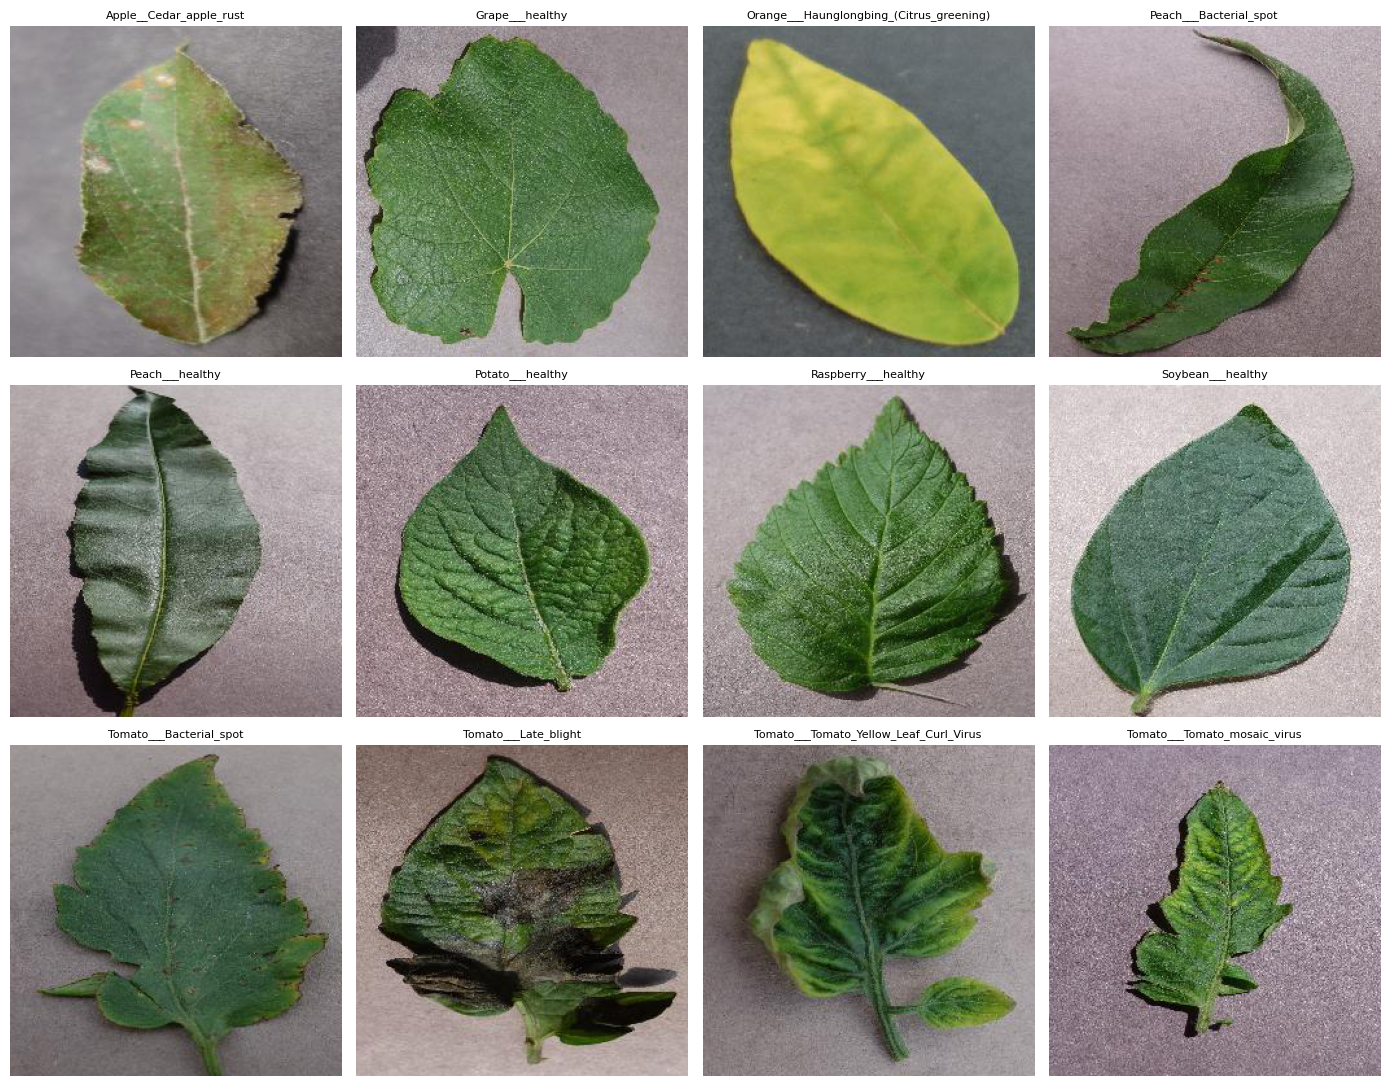

In [3]:
from PIL import Image

selected_classes = list(class_counts.head(6).index) + list(class_counts.tail(6).index)

sample_rows = (
    images[images["class_name"].isin(selected_classes)]
    .groupby("class_name", group_keys=False)
    .sample(n=1, random_state=42)
)

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    with Image.open(row["path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(row["class_name"], fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_rows):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Data Quality

In [7]:
from PIL import Image

image_quality_rows = []
corrupt_images = []

total_images = len(images)

for i, row in enumerate(
    images[["path", "class_name"]].itertuples(index=False),
    start=1
):
    try:
        with Image.open(row.path) as image:
            width, height = image.size
            mode = image.mode
            image_format = image.format
            image.verify()

        image_quality_rows.append({
            "path": row.path,
            "class_name": row.class_name,
            "width": width,
            "height": height,
            "mode": mode,
            "format": image_format,
        })

    except Exception as exc:
        corrupt_images.append({
            "path": row.path,
            "class_name": row.class_name,
            "error": f"{type(exc).__name__}: {exc}",
        })

    if i % 5000 == 0 or i == total_images:
        print(f"Đã kiểm tra {i:,}/{total_images:,} ảnh")

image_quality = pd.DataFrame(image_quality_rows)
corrupt_images = pd.DataFrame(corrupt_images)

print(f"\nẢnh đọc/kiểm tra thành công: {len(image_quality):,}")
print(f"Ảnh lỗi: {len(corrupt_images):,}")
print(f"File có kích thước bằng 0: {(images['size_bytes'] == 0).sum():,}")

print("\nCác kích thước ảnh phổ biến:")
display(
    image_quality.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("image_count")
    .to_frame()
)

print("\nChế độ màu:")
display(image_quality["mode"].value_counts().rename("image_count").to_frame())

if not corrupt_images.empty:
    print("\nMột số ảnh lỗi:")
    display(corrupt_images.head(10))

Đã kiểm tra 5,000/54,381 ảnh
Đã kiểm tra 10,000/54,381 ảnh
Đã kiểm tra 15,000/54,381 ảnh
Đã kiểm tra 20,000/54,381 ảnh
Đã kiểm tra 25,000/54,381 ảnh
Đã kiểm tra 30,000/54,381 ảnh
Đã kiểm tra 35,000/54,381 ảnh
Đã kiểm tra 40,000/54,381 ảnh
Đã kiểm tra 45,000/54,381 ảnh
Đã kiểm tra 50,000/54,381 ảnh
Đã kiểm tra 54,381/54,381 ảnh

Ảnh đọc/kiểm tra thành công: 54,381
Ảnh lỗi: 0
File có kích thước bằng 0: 0

Các kích thước ảnh phổ biến:


,,image_count
width,height,
256,256,54381



Chế độ màu:


,image_count
mode,
RGB,54381


Univariate Analysis

Số ảnh được lấy mẫu: 380
Thống kê độ sáng trung bình trên mỗi ảnh:


,count,mean,std,min,25%,50%,75%,max
mean_brightness,380.0,122.306850,17.071923,65.076920,113.962753,121.959511,131.650318,195.235550
std_brightness,380.0,41.260477,11.092043,14.111231,33.529435,41.308214,49.207695,81.326577


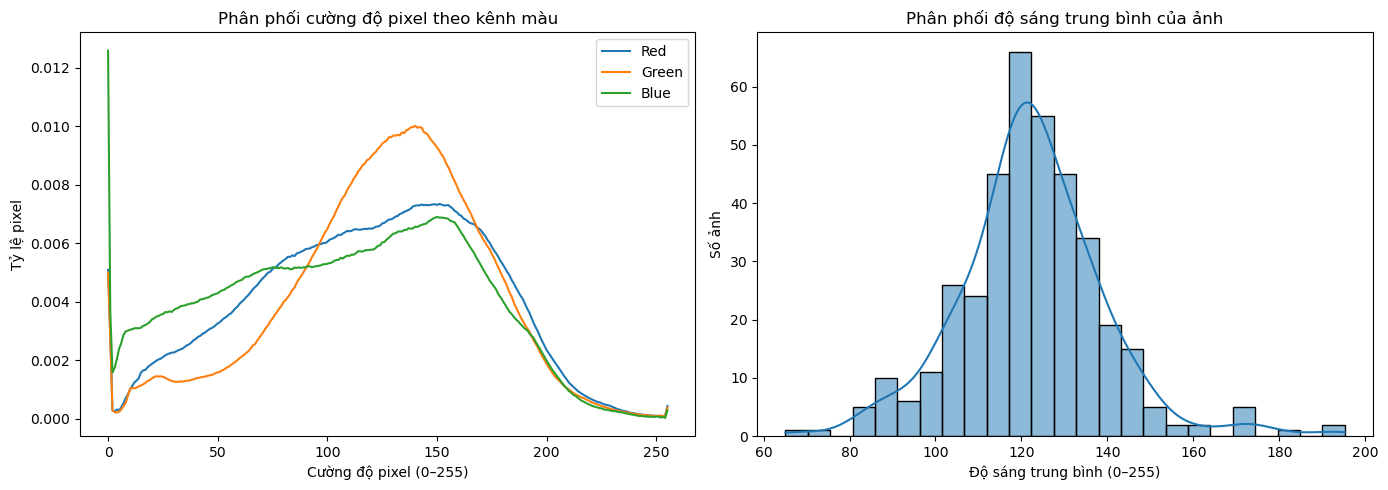

In [8]:
import numpy as np
from PIL import Image

# Lấy mẫu cân bằng: 10 ảnh cho mỗi lớp
sampled_images = (
    images.groupby("class_name", group_keys=False)
    .sample(n=10, random_state=42)
)

channel_names = ["Red", "Green", "Blue"]
channel_histograms = {
    channel: np.zeros(256, dtype=np.int64)
    for channel in channel_names
}
brightness_records = []

for row in sampled_images[["path", "class_name"]].itertuples(index=False):
    with Image.open(row.path) as image:
        rgb = np.asarray(image.convert("RGB"), dtype=np.uint8)
        gray = np.asarray(image.convert("L"), dtype=np.uint8)

    for channel_index, channel_name in enumerate(channel_names):
        channel_histograms[channel_name] += np.bincount(
            rgb[:, :, channel_index].ravel(),
            minlength=256
        )

    brightness_records.append({
        "class_name": row.class_name,
        "mean_brightness": gray.mean(),
        "std_brightness": gray.std(),
    })

brightness_df = pd.DataFrame(brightness_records)

print(f"Số ảnh được lấy mẫu: {len(sampled_images)}")
print("Thống kê độ sáng trung bình trên mỗi ảnh:")
display(brightness_df[["mean_brightness", "std_brightness"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Phân phối cường độ pixel theo từng kênh màu
pixel_values = np.arange(256)

for channel_name, histogram in channel_histograms.items():
    normalized_histogram = histogram / histogram.sum()
    axes[0].plot(pixel_values, normalized_histogram, label=channel_name)

axes[0].set_title("Phân phối cường độ pixel theo kênh màu")
axes[0].set_xlabel("Cường độ pixel (0–255)")
axes[0].set_ylabel("Tỷ lệ pixel")
axes[0].legend()

# Phân phối độ sáng trung bình giữa các ảnh mẫu
sns.histplot(
    data=brightness_df,
    x="mean_brightness",
    bins=25,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Phân phối độ sáng trung bình của ảnh")
axes[1].set_xlabel("Độ sáng trung bình (0–255)")
axes[1].set_ylabel("Số ảnh")

plt.tight_layout()
plt.show()

Bivariate Analysis

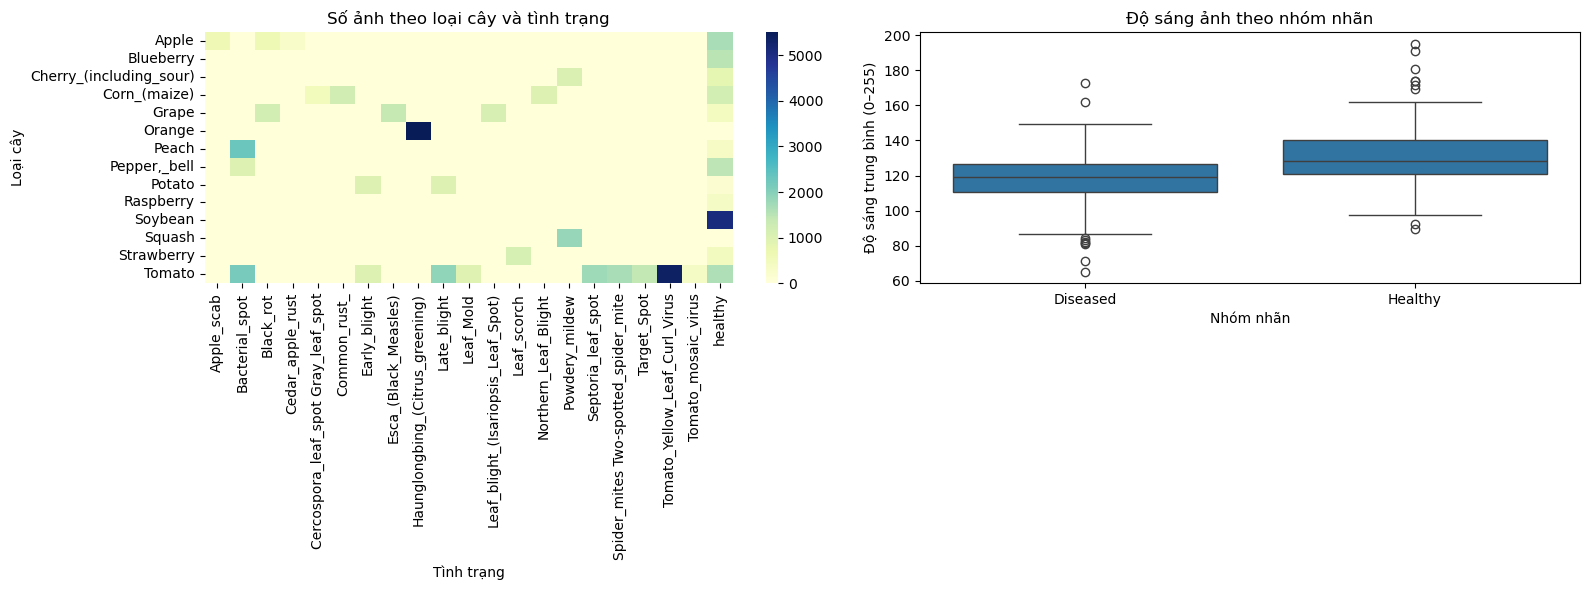

In [9]:
# Bổ sung nhãn cây và tình trạng vào thống kê độ sáng của mẫu ảnh
label_info = images[
    ["class_name", "crop", "condition"]
].drop_duplicates()

brightness_by_image = brightness_df.merge(
    label_info,
    on="class_name",
    how="left",
    validate="many_to_one"
)

brightness_by_image["health_status"] = np.where(
    brightness_by_image["condition"].str.lower().eq("healthy"),
    "Healthy",
    "Diseased"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Số ảnh theo tổ hợp loại cây và tình trạng
crop_condition_counts = (
    images.groupby(["crop", "condition"])
    .size()
    .unstack(fill_value=0)
)

sns.heatmap(
    crop_condition_counts,
    cmap="YlGnBu",
    ax=axes[0]
)
axes[0].set_title("Số ảnh theo loại cây và tình trạng")
axes[0].set_xlabel("Tình trạng")
axes[0].set_ylabel("Loại cây")
axes[0].tick_params(axis="x", rotation=90)

# So sánh độ sáng trung bình giữa ảnh khỏe và ảnh bệnh
sns.boxplot(
    data=brightness_by_image,
    x="health_status",
    y="mean_brightness",
    ax=axes[1]
)
axes[1].set_title("Độ sáng ảnh theo nhóm nhãn")
axes[1].set_xlabel("Nhóm nhãn")
axes[1].set_ylabel("Độ sáng trung bình (0–255)")

plt.tight_layout()
plt.show()

Target Analysis

Top 10 lớp có nhiều ảnh nhất:


,image_count,share_percent
class_name,,
Orange___Haunglongbing_(Citrus_greening),5507,10.13
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.85
Soybean___healthy,5090,9.36
Peach___Bacterial_spot,2297,4.22
Tomato___Bacterial_spot,2137,3.93
Tomato___Late_blight,1909,3.51
Squash___Powdery_mildew,1835,3.37
Tomato___Septoria_leaf_spot,1771,3.26
Tomato___Spider_mites Two-spotted_spider_mite,1676,3.08


10 lớp có ít ảnh nhất:


,image_count,share_percent
class_name,,
Apple__Apple_scab,631,1.16
Apple__Black_rot,621,1.14
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,514,0.95
Strawberry___healthy,456,0.84
Grape___healthy,423,0.78
Tomato___Tomato_mosaic_virus,373,0.69
Raspberry___healthy,371,0.68
Peach___healthy,360,0.66
Apple__Cedar_apple_rust,285,0.52


Tỷ lệ ảnh theo nhóm khỏe/bệnh:


,image_count,share_percent
health_status,,
Diseased,39243,72.16
Healthy,15138,27.84


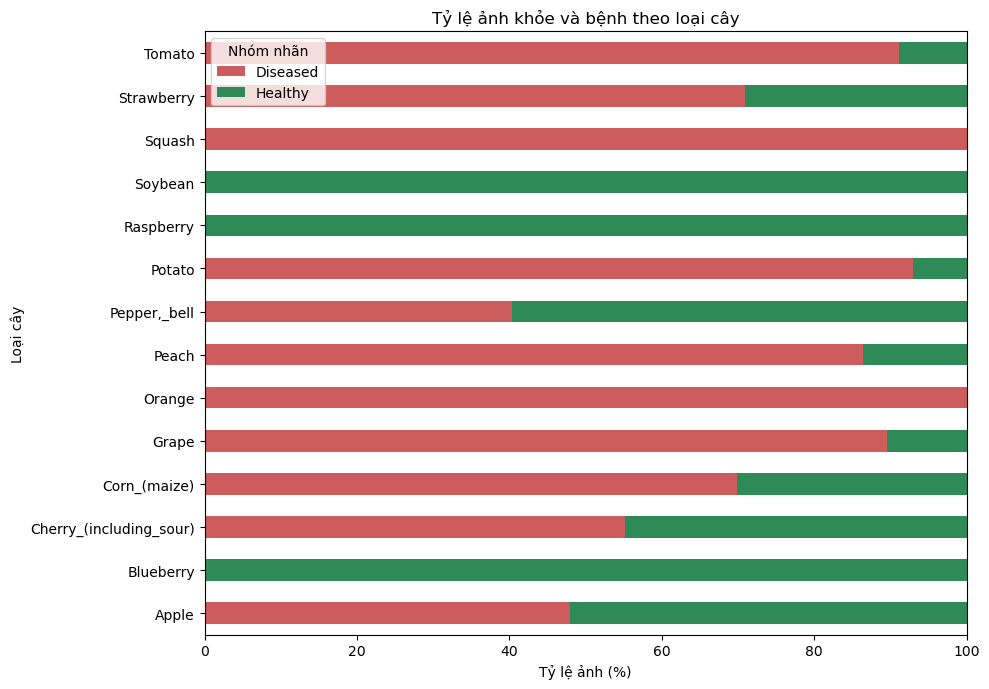

In [10]:
# Nhãn chính là 38 lớp cây + tình trạng
target_counts = images["class_name"].value_counts().sort_values(ascending=False)

target_summary = pd.DataFrame({
    "image_count": target_counts,
    "share_percent": target_counts / target_counts.sum() * 100
})

print("Top 10 lớp có nhiều ảnh nhất:")
display(target_summary.head(10).round(2))

print("10 lớp có ít ảnh nhất:")
display(target_summary.tail(10).round(2))

# Nhóm phụ: khỏe mạnh hoặc có bệnh
images["health_status"] = np.where(
    images["condition"].str.casefold().eq("healthy"),
    "Healthy",
    "Diseased"
)

health_counts = images["health_status"].value_counts()

print("Tỷ lệ ảnh theo nhóm khỏe/bệnh:")
display(
    pd.DataFrame({
        "image_count": health_counts,
        "share_percent": health_counts / len(images) * 100
    }).round(2)
)

# Tỷ lệ khỏe/bệnh trong từng loại cây
health_by_crop = pd.crosstab(
    images["crop"],
    images["health_status"],
    normalize="index"
) * 100

health_by_crop.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 7),
    color={"Diseased": "indianred", "Healthy": "seagreen"}
)

plt.title("Tỷ lệ ảnh khỏe và bệnh theo loại cây")
plt.xlabel("Tỷ lệ ảnh (%)")
plt.ylabel("Loại cây")
plt.xlim(0, 100)
plt.legend(title="Nhóm nhãn")
plt.tight_layout()
plt.show()

Domain-specific EDA

Lớp khỏe: Tomato___healthy
Lớp bệnh được chọn: Tomato___Tomato_Yellow_Leaf_Curl_Virus


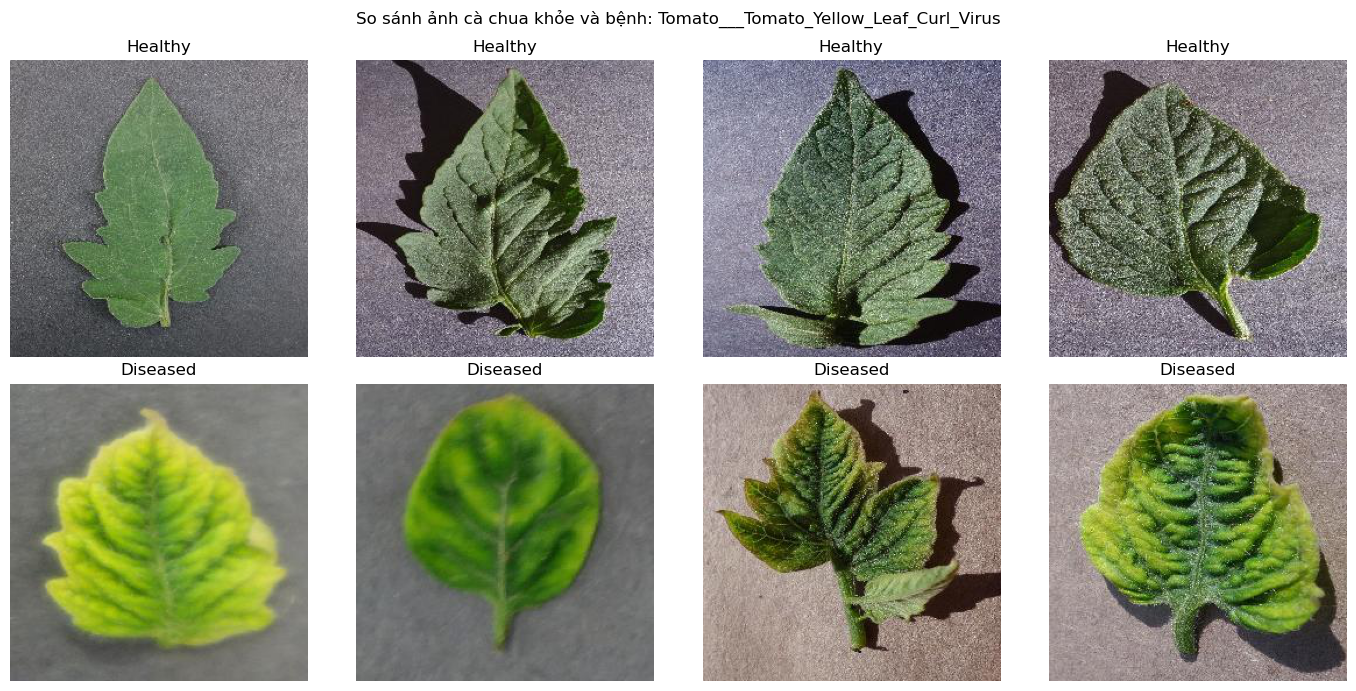

In [11]:
from PIL import Image

SELECT_CROP = "Tomato"
N_IMAGES_PER_GROUP = 4

tomato_df = images[images["crop"].eq(SELECT_CROP)].copy()

healthy_classes = tomato_df.loc[
    tomato_df["health_status"].eq("Healthy"),
    "class_name"
].unique()

diseased_classes = tomato_df.loc[
    tomato_df["health_status"].eq("Diseased"),
    "class_name"
].value_counts()

if len(healthy_classes) == 0 or diseased_classes.empty:
    raise ValueError(
        f"Không tìm thấy cả hai nhóm khỏe/bệnh cho loại cây {SELECT_CROP}"
    )

healthy_class = healthy_classes[0]
disease_class = diseased_classes.index[0]

print("Lớp khỏe:", healthy_class)
print("Lớp bệnh được chọn:", disease_class)

healthy_samples = (
    tomato_df[tomato_df["class_name"].eq(healthy_class)]
    .sample(n=min(N_IMAGES_PER_GROUP, (tomato_df["class_name"] == healthy_class).sum()),
            random_state=42)
)

disease_samples = (
    tomato_df[tomato_df["class_name"].eq(disease_class)]
    .sample(n=min(N_IMAGES_PER_GROUP, (tomato_df["class_name"] == disease_class).sum()),
            random_state=42)
)

fig, axes = plt.subplots(2, N_IMAGES_PER_GROUP, figsize=(14, 7))

for row_idx, (label, sample_df) in enumerate([
    ("Healthy", healthy_samples),
    ("Diseased", disease_samples),
]):
    for col_idx in range(N_IMAGES_PER_GROUP):
        ax = axes[row_idx, col_idx]

        if col_idx < len(sample_df):
            row = sample_df.iloc[col_idx]
            with Image.open(row["path"]) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(label)
        ax.axis("off")

plt.suptitle(f"So sánh ảnh cà chua khỏe và bệnh: {disease_class}")
plt.tight_layout()
plt.show()

EDA Conclusion

### Kết luận EDA

- Bộ dữ liệu có **54.381 ảnh**, thuộc **38 lớp** (kết hợp loại cây và tình trạng), gồm **14 loại cây** và **21 tình trạng**. Tất cả ảnh đều là JPG, kích thước 256 × 256, chế độ RGB; kiểm tra toàn bộ ảnh không phát hiện ảnh lỗi hoặc file rỗng.
- Số lượng ảnh giữa các lớp chênh lệch đáng kể: lớp lớn nhất có **5.507 ảnh**, lớp nhỏ nhất có **152 ảnh**, tức chênh khoảng **36,2 lần**. Vì vậy, cần lưu ý mất cân bằng lớp khi chia dữ liệu và đánh giá mô hình.
- Trong bộ dữ liệu, ảnh bệnh chiếm **72,16%**, ảnh khỏe chiếm **27,84%**. Tỷ lệ này mô tả bộ dữ liệu hiện có, không đại diện cho tỷ lệ bệnh ngoài thực tế.
- Quan sát mẫu ảnh cho thấy điều kiện chụp có khác biệt về ánh sáng, bóng đổ, góc chụp và hình dạng lá. Ở mẫu cà chua được xem, lá thuộc lớp khỏe thường phẳng và xanh hơn, còn một số lá thuộc lớp Tomato Yellow Leaf Curl Virus có biểu hiện vàng và quăn. Đây là nhận xét từ ảnh mẫu, chưa đủ để khẳng định dấu hiệu này áp dụng cho mọi lớp.
- Phân bố độ sáng của ảnh khỏe và ảnh bệnh có phần chồng lấp. Do đó, không nên dựa riêng vào độ sáng để phân biệt tình trạng lá; mô hình cần học đặc trưng hình ảnh phong phú hơn.
- Heatmap cho thấy không phải mọi loại cây đều có đủ các tình trạng khỏe/bệnh. Khi huấn luyện, nên dùng **chia tập có phân tầng theo 38 lớp** và xem thêm precision, recall, F1-score theo từng lớp cùng macro-F1. Cần thận trọng khi diễn giải kết quả cho các lớp có ít ảnh.

**Định hướng tiền xử lý:** chuẩn hóa pixel, áp dụng tăng cường ảnh phù hợp với biến thiên góc chụp và ánh sáng, đồng thời giữ nguyên thông tin màu vì màu sắc có thể hữu ích cho nhận diện triệu chứng. Chỉ áp dụng các phép biến đổi không làm thay đổi ý nghĩa nhãn.